In [40]:
# import things
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K

In [41]:
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives+K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives+K.epsilon())
        return precision
    
    precision, recall = precision_m(y_true, y_pred), recall_m(y_true, y_pred)
    
    return 2*((precision*recall)/(precision+recall+K.epsilon()))

In [42]:
# Load the model you trained in task5_training.ipynb
from tensorflow.keras.models import load_model
patch_size = 256
example_file_name ='MoaliJaberi_244437_unet_model_256px.h5'
model = load_model(example_file_name, custom_objects={"f1": f1})

In [43]:
# Define any functions you need to process the mask e.g. Task 2
def prepare_petri_dish_from_gray(image_gray, output_size=2736):
    image_rgb = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2RGB)

    lab = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    image_rgb_clahe = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    h, w = image_rgb_clahe.shape[:2]
    center_y, center_x = h // 2, w // 2
    half = output_size // 2
    start_y, start_x = center_y - half, center_x - half
    petri_dish = image_rgb_clahe[start_y:start_y + output_size, start_x:start_x + output_size]
    return petri_dish


In [44]:
# Load the test image
task5_test_image_path = 'task5_test_image.png'
image = cv2.imread(task5_test_image_path, 0)
h, w = image.shape
print(h, w)

3006 4112


In [45]:
# Find the petri dish
petri_dish = prepare_petri_dish_from_gray(image)
petri_dish.shape

(2736, 2736, 3)

In [46]:
# Pad the petri dish
def pad_to_target_size(image, target_size=2816):
    h, w = image.shape[:2]
    assert h == w
    pad_total = target_size - h
    pad_before = pad_total // 2
    pad_after = pad_total - pad_before
    padded = np.pad(image, ((pad_before, pad_after), (pad_before, pad_after), (0, 0)), mode='constant', constant_values=0)
    return padded, (pad_before, pad_after)

petri_dish_padded, (pad_top, pad_bottom) = pad_to_target_size(petri_dish)
petri_dish_padded.shape

(2816, 2816, 3)

Extracted 121 patches of size 256x256
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 666ms/step
Predicted mask shape: (2816, 2816)


Text(0.5, 1.0, 'Prediction')

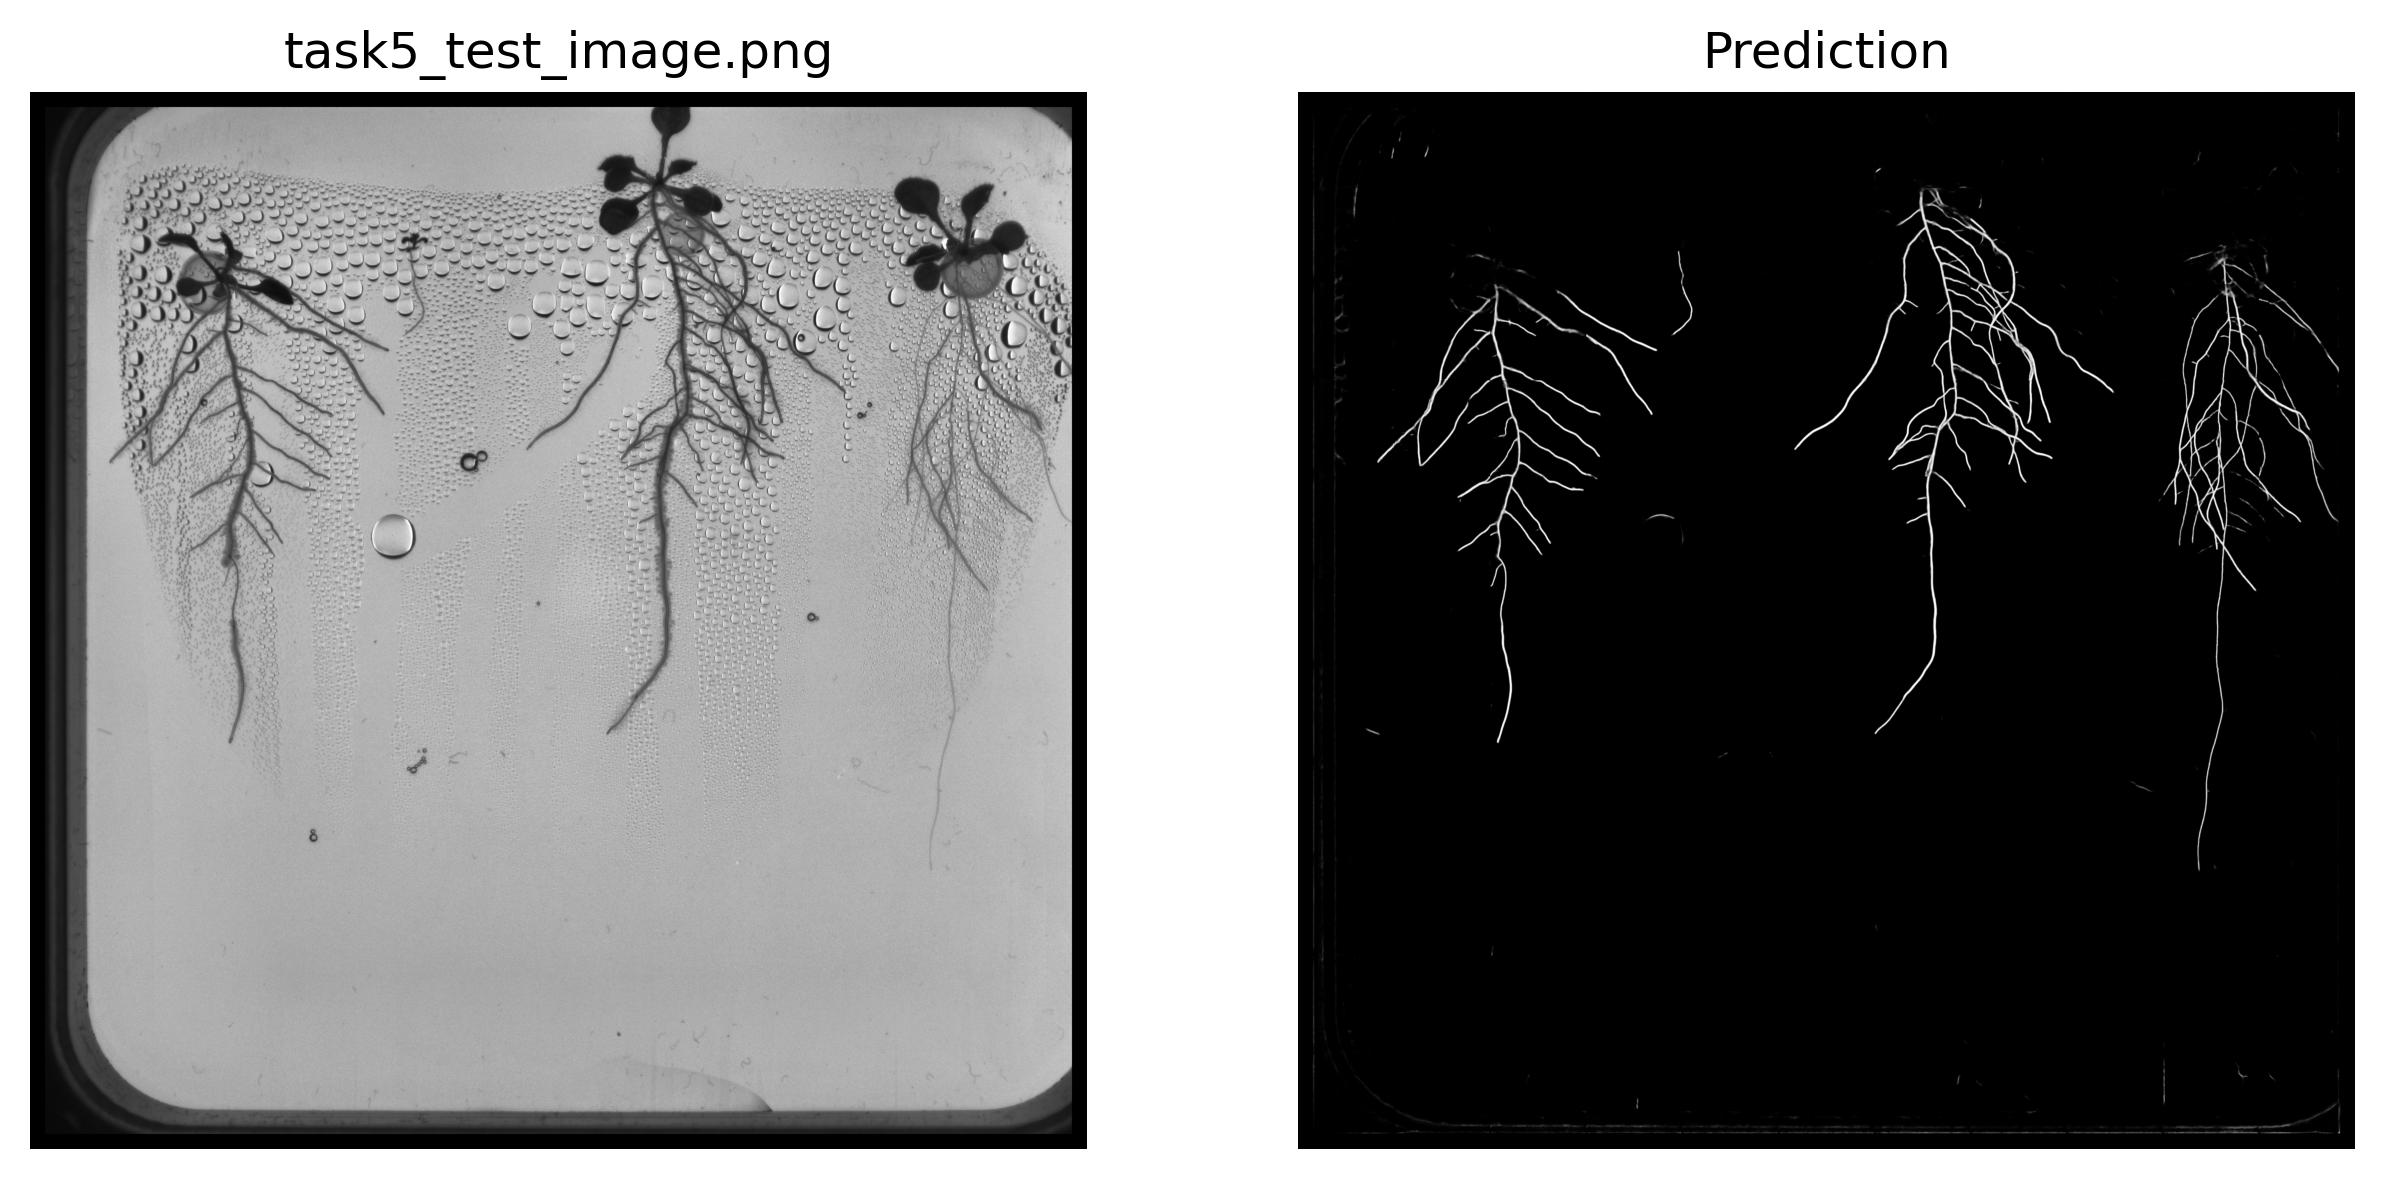

In [47]:
# PATCH
def patch_image(image, patch_size=256):
    h, w = image.shape[:2]
    patches = []
    for y in range(0, h, patch_size):
        for x in range(0, w, patch_size):
            patch = image[y:y+patch_size, x:x+patch_size]
            patches.append(patch)
    rows, cols = h // patch_size, w // patch_size
    return np.array(patches), rows, cols

patches, rows, cols = patch_image(petri_dish_padded)
print(f"Extracted {len(patches)} patches of size 256x256")
# PREDICT
patches_norm = patches.astype(np.float32) / 255.0
preds = model.predict(patches_norm, batch_size=4, verbose=1)
preds_squeezed = np.squeeze(preds, axis=-1) 

# UNPATCH
def unpatch_mask(pred_patches, rows, cols, patch_size=256):
    full_mask = np.zeros((rows * patch_size, cols * patch_size), dtype=np.float32)
    idx = 0
    for i in range(rows):
        for j in range(cols):
            y, x = i * patch_size, j * patch_size
            full_mask[y:y+patch_size, x:x+patch_size] = pred_patches[idx]
            idx += 1
    return full_mask

predicted_mask = unpatch_mask(preds_squeezed, rows, cols)
print("Predicted mask shape:", predicted_mask.shape)
f, ax = plt.subplots(1, 2, dpi=300, figsize=(10, 5))
ax[0].imshow(petri_dish_padded, cmap='gray')
ax[0].axis('off')
ax[0].set_title('task5_test_image.png')
ax[1].imshow(predicted_mask, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Prediction')

In [48]:
predicted_mask.shape, image.shape

((2816, 2816), (3006, 4112))

As you can see `predicted_mask` and `image` have different shapes. This is because of cropping and padding.

**REQUIREMENT:** The input and output should have the same size and should be aligned perfectly. To achieve this, you need to reverse the effects of cropping and padding added during processing. This will ensure the final mask aligns with the original image.

In [50]:
# Apply the corrections
# Step 1: remove padding, already done earlier
predicted_mask_unpadded = predicted_mask[pad_top:pad_top+2736, pad_top:pad_top+2736]

# Step 2: Initialize full-size blank canvas
corrected_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)  # shape: 3006 × 4112

# Step 3: Compute coordinates for center-paste
center_y = image.shape[0] // 2
center_x = image.shape[1] // 2
half = 2736 // 2
start_y = center_y - half
start_x = center_x - half

# Step 4: Threshold + paste mask into full-size image
binary_mask = (predicted_mask_unpadded > 0.5).astype(np.uint8)
corrected_mask[start_y:start_y + 2736, start_x:start_x + 2736] = binary_mask
predicted_mask_corrected = corrected_mask
predicted_mask_corrected.shape


(3006, 4112)

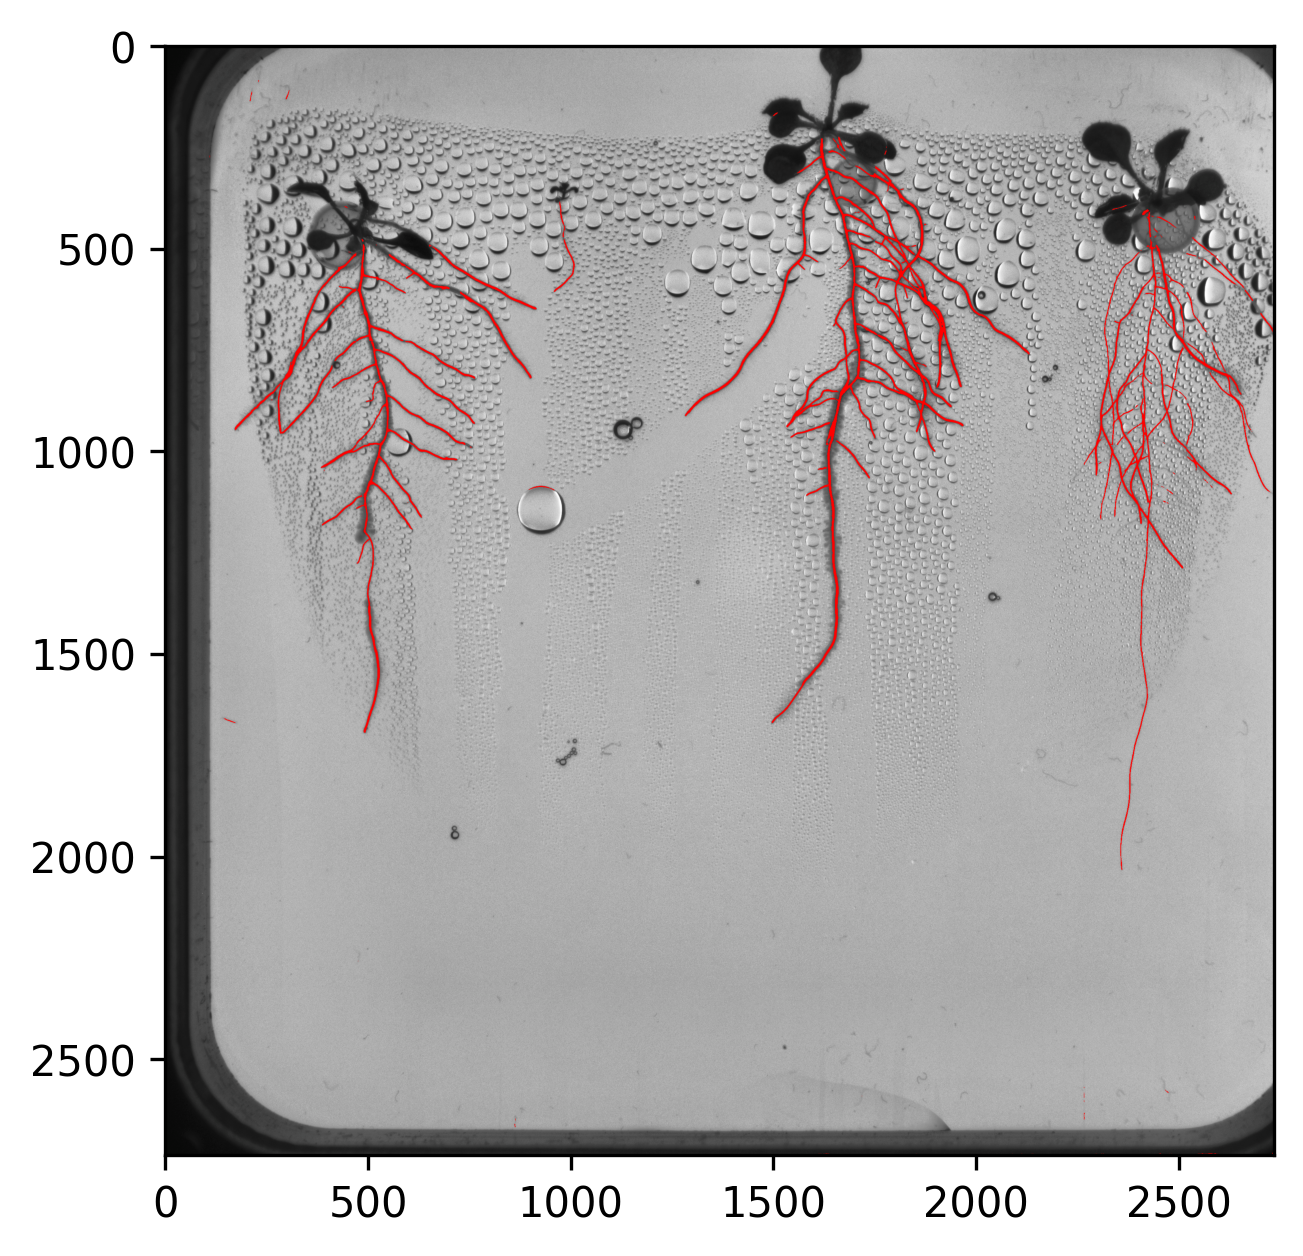

In [52]:
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: Plot such an image to prove alignment.

plt.figure(dpi=300)
plt.imshow(overlay)

In [54]:
# REQUIREMENT: Save the predicted mask, it is a deliverable.
# REQUIREMENT: Input/Output size must be the same.
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: The predicted mask must be binary.
# REQUIREMENT: Non-root pixels must be 0, root pixels must be 255 (unlike Task 1)
# REQUIREMENT: naming convention task5_test_image_prediction_studentname_studentnumber.png
mask_image = (predicted_mask_corrected * 255).astype(np.uint8)
assert(predicted_mask_corrected.shape == image.shape)
cv2.imwrite('task5_test_image_prediction_Mohammadali_244437.png', mask_image)

True

Note: I have trained the model on the Y2B_23 dataset, since there are no labels for Y2B_24 dataset yet. The test image is from Y2B_24, this is why the predicted mask is suboptimal. Therefore do not take the performance of this prediction as a reference. Your predictions should be much better than this.